In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns


In [2]:
df = pd.read_csv("credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## EDA

In [3]:
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [4]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [5]:
df['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

In [6]:
numrical_col = df.select_dtypes(include=np.number).columns
print(numrical_col)


Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='str')


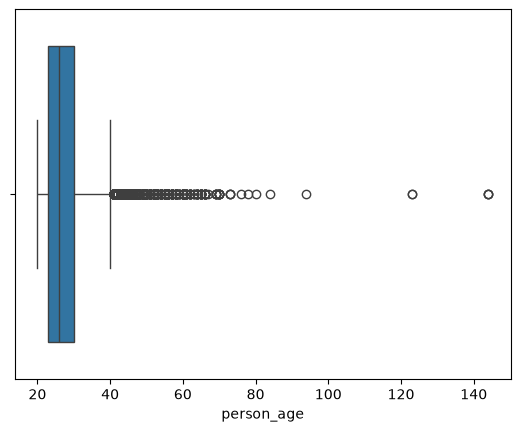

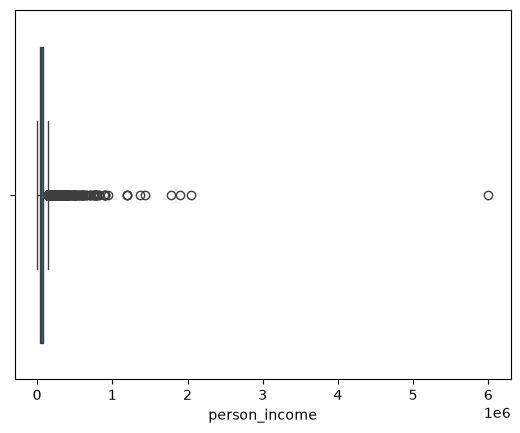

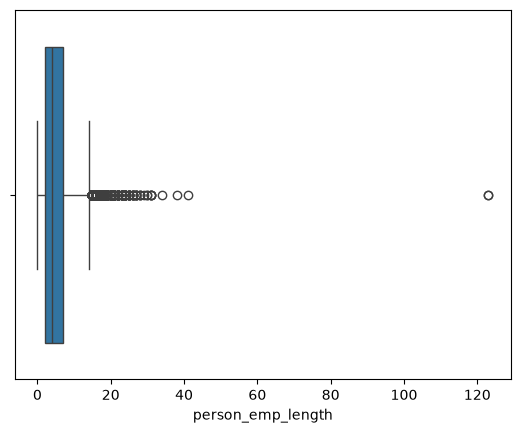

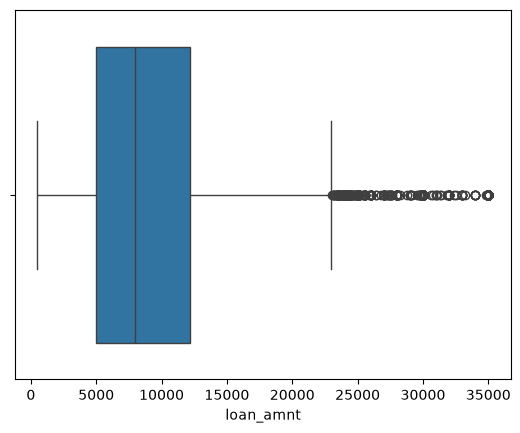

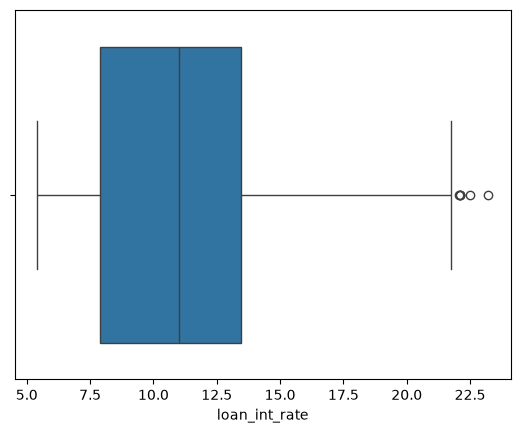

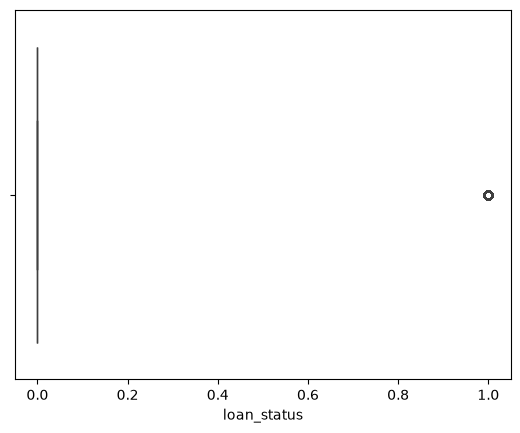

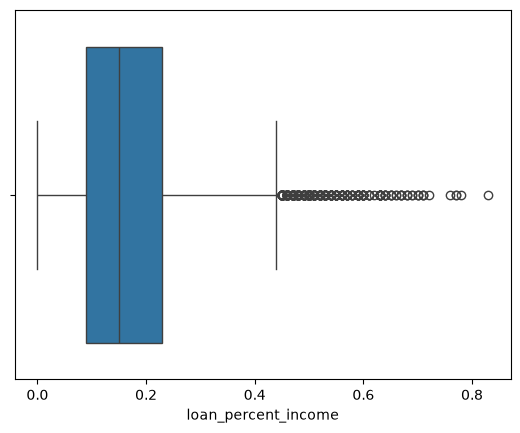

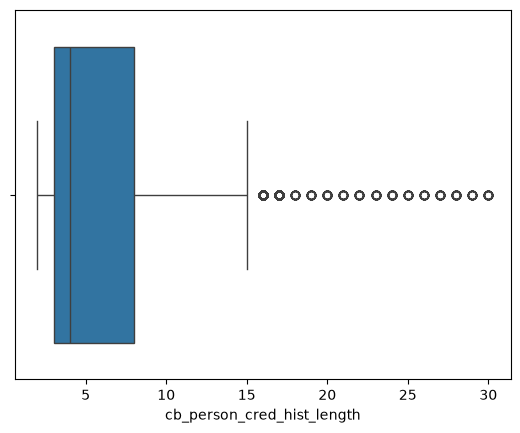

In [7]:
for i in numrical_col:
    sns.boxplot(x=df[i])
    plt.show()

In [8]:
(df['person_age'] > 100).sum()

np.int64(5)

In [9]:
df['person_emp_length'].max()

np.float64(123.0)

<Axes: >

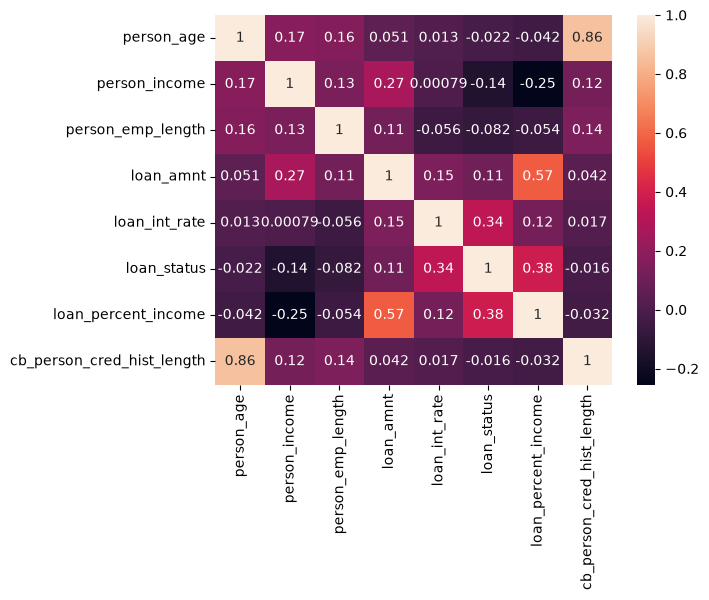

In [10]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

## Data Valifdation & outlier handaling

In [11]:
df_copy = df.copy()

In [12]:
print("Original Rows :",df_copy.shape[0])
df_copy.drop_duplicates(inplace=True)
print("Rows after removing duplicate rows: ",df_copy.shape[0])

Original Rows : 32581
Rows after removing duplicate rows:  32416


In [13]:
df_copy = df_copy[(df_copy['person_age'] >= 18) & (df_copy['person_age'] <= 100)]
df_copy.shape[0]

32411

In [14]:
df_copy = df_copy[
    df_copy['person_emp_length'].isna() |
    (df_copy['person_emp_length'] <= df_copy['person_age'])
]

df_copy = df_copy[
    df_copy['person_emp_length'].isna() |
    (df_copy['person_emp_length'] <= 60)
]

In [15]:
df_copy = df_copy[df_copy['loan_amnt']>0]

In [16]:
print(f"Loan interest rate range from min:{df_copy['loan_int_rate'].min()} and max:{df_copy['loan_int_rate'].max()}")

Loan interest rate range from min:5.42 and max:23.22


## Feature , Target & train-test split 

In [17]:
x = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status']

In [18]:
from sklearn.model_selection import train_test_split

# First, keep 20% of the full dataset untouched for final testing.
x_dev, x_test, y_dev, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the remaining 80% into training (60% overall) and validation (20% overall).
# The validation set is used for threshold selection, never the test set.
x_train, x_val, y_train, y_val = train_test_split(
    x_dev,
    y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Training rows:", len(x_train))
print("Validation rows:", len(x_val))
print("Final test rows:", len(x_test))


Training rows: 19445
Validation rows: 6482
Final test rows: 6482


In [19]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

## Handle Class Imbalance

In [20]:
y_train.value_counts()

loan_status
0    15193
1     4252
Name: count, dtype: int64

In [21]:
# here is imbalance b/w o/p , so we need to handle this

In [22]:
neg, pos = np.bincount(y_train)

scale_pos_weight = neg / pos

print("Negative samples:", neg)
print("Positive samples:", pos)
print("Scale Pos Weight:", scale_pos_weight)

Negative samples: 15193
Positive samples: 4252
Scale Pos Weight: 3.573142050799624


## Trainig Model

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        #pipeline for numerical col
        ('num', Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('scalar',StandardScaler())
        ]), numeric_cols),

        #pipeline for categorical col
        ('cat', Pipeline([
            ('imputer',SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
        
    ]
)

In [24]:
#XGBoost: Impute numeric only (No Scaling), impute + One - Hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])


In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_auc_score
)

def evaluate_model(model_name, model, X_test, y_test, threshold=None):

    y_pred_prob = model.predict_proba(X_test)[:, 1]

    if threshold is not None:
        y_pred = (y_pred_prob >= threshold).astype(int)
    else:
        y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_pred_prob)

    conf_matrix = confusion_matrix(y_test, y_pred)

    print(f"\n{model_name} Metrics")
    print("--------------------------")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1 Score  : {f1:.4f}")
    print(f"ROC-AUC   : {roc_auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

    # Confusion Matrix
    sns.heatmap(conf_matrix, annot=True, fmt="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()

    # Precision-Recall Curve
    precisions, recalls, thresholds = precision_recall_curve(
        y_test, y_pred_prob
    )

    plt.plot(recalls, precisions)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

In [26]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

In [27]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [28]:
from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),

    ('classifier', XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric='logloss'
    ))
])

In [29]:
for cv_name, pipe in [
    ("Logistic Regression", lr_cv_pipeline),
    ("XGBoost", xgb_cv_pipeline)
]:

    cv_results = cross_validate(
        pipe,
        x_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    print(cv_name)
    print(f"ROC-AUC: {cv_results['test_roc_auc'].mean():.4f}")
    print(f"Accuracy: {cv_results['test_accuracy'].mean():.4f}")
    print(f"Precision: {cv_results['test_precision'].mean():.4f}")
    print(f"Recall: {cv_results['test_recall'].mean():.4f}")
    print(f"F1: {cv_results['test_f1'].mean():.4f}")
    print()

Logistic Regression
ROC-AUC: 0.8708
Accuracy: 0.8120
Precision: 0.5500
Recall: 0.7761
F1: 0.6436

XGBoost
ROC-AUC: 0.9429
Accuracy: 0.9172
Precision: 0.8266
Recall: 0.7862
F1: 0.8058



In [30]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),

    ('classifier', LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

baseline_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

## Evaluate logistic model


Baseline Logistic Model Metrics
--------------------------
Accuracy  : 0.8195
Precision : 0.5643
Recall    : 0.7673
F1 Score  : 0.6503
ROC-AUC   : 0.8691

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      5064
           1       0.56      0.77      0.65      1418

    accuracy                           0.82      6482
   macro avg       0.75      0.80      0.76      6482
weighted avg       0.85      0.82      0.83      6482



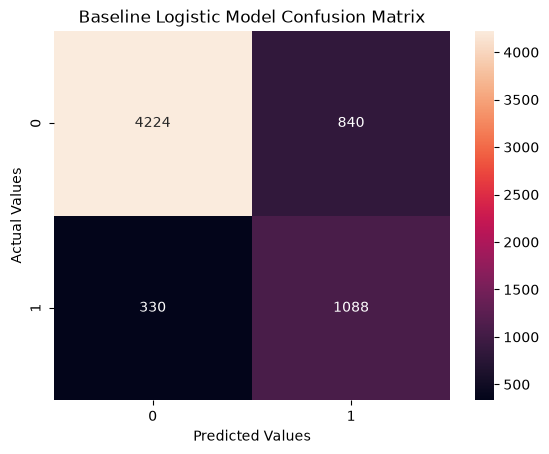

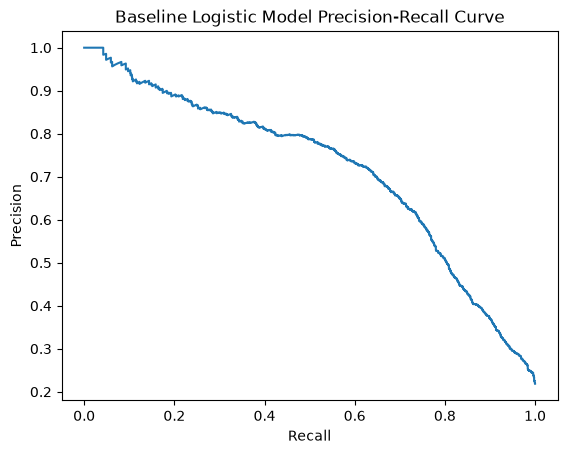

In [31]:
evaluate_model("Baseline Logistic Model", baseline_model, x_val, y_val)

## XGBOOST Hyperparameter tunning

In [32]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),

    ('classifier', XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric='logloss'
    ))
])

In [33]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}
# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits ->  simpler tree -> low overfitting

In [34]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(x_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': <scipy.stats....001570B0CE120>, 'classifier__gamma': <scipy.stats....001570B195190>, 'classifier__learning_rate': <scipy.stats....001570B0CE2D0>, 'classifier__max_depth': <scipy.stats....001570B0B1130>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",150
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index

In [35]:
print(f"Score after performing Tunning {random_search.best_score_:.2f}")

Score after performing Tunning 0.90


In [36]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.6379989017735391),
 'classifier__gamma': np.float64(2.027880044801286),
 'classifier__learning_rate': np.float64(0.09034437467562266),
 'classifier__max_depth': 7,
 'classifier__min_child_weight': 5,
 'classifier__n_estimators': 301,
 'classifier__subsample': np.float64(0.9711680719150001)}

## Compare both models side by side


Logistic Regression Metrics
--------------------------
Accuracy  : 0.8195
Precision : 0.5643
Recall    : 0.7673
F1 Score  : 0.6503
ROC-AUC   : 0.8691

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      5064
           1       0.56      0.77      0.65      1418

    accuracy                           0.82      6482
   macro avg       0.75      0.80      0.76      6482
weighted avg       0.85      0.82      0.83      6482



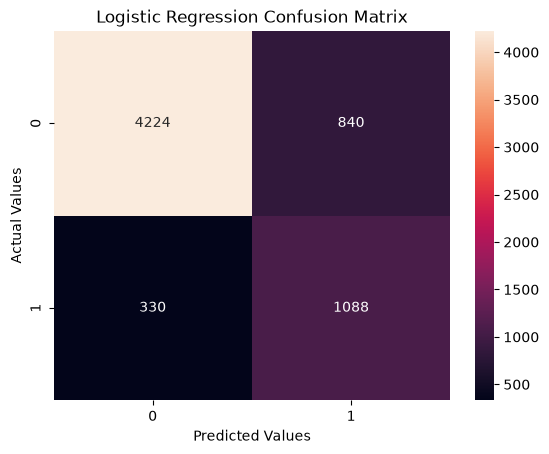

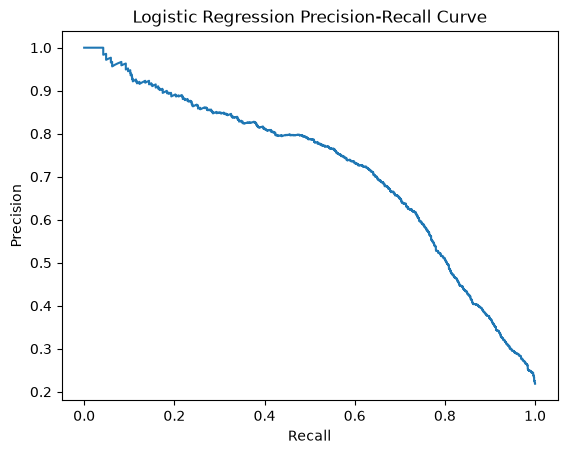

In [37]:
evaluate_model("Logistic Regression", baseline_model, x_val, y_val)


XGBoost Metrics
--------------------------
Accuracy  : 0.9168
Precision : 0.8302
Recall    : 0.7793
F1 Score  : 0.8039
ROC-AUC   : 0.9443

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95      5064
           1       0.83      0.78      0.80      1418

    accuracy                           0.92      6482
   macro avg       0.88      0.87      0.88      6482
weighted avg       0.92      0.92      0.92      6482



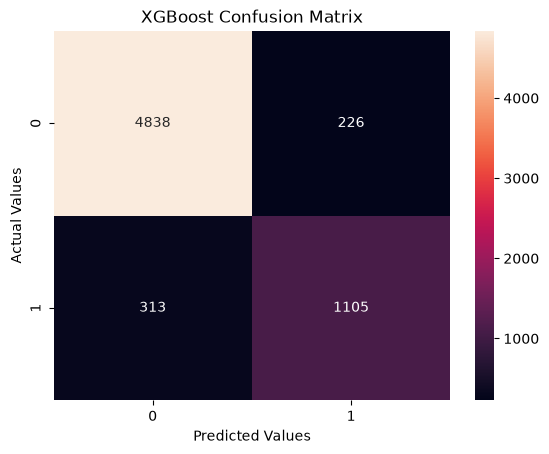

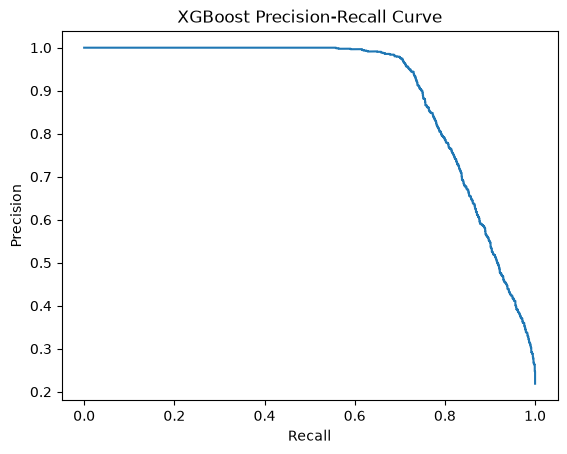

In [38]:
# Compare the tuned XGBoost model on the validation set during model development.
# Do not use the final test set to choose models or thresholds.
evaluate_model("XGBoost", random_search, x_val, y_val)


## Optimizing the classification threshold

In [39]:
# Threshold selection is performed AFTER probability calibration.
# This cell intentionally does not use x_test or y_test.
# See the "Threshold selection using validation set" section below.


## Probability Calibration 

In [40]:
"""
Methods by which we can fix the poorly calibrated model.
1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)
3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature
"""

'\nMethods by which we can fix the poorly calibrated model.\n1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.\n2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)\n3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature\n'

In [41]:
# Calibrate the tuned XGBoost model using training data only.
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

best_model = random_search.best_estimator_

calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(x_train, y_train)


,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","Pipeline(step...=None, ...))])"
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...001570B1ACC20>, <

In [42]:
# Compare uncalibrated and calibrated probabilities on the validation set.
# Use the same tuned estimator as the calibrated model's base estimator.
uncalibrated = best_model.predict_proba(x_val)[:, 1]
calibrated = calibrated_model.predict_proba(x_val)[:, 1]


In [43]:
# Calibration curve before calibration (validation set).
actual_uncal, predicted_uncal = calibration_curve(
    y_val,
    uncalibrated,
    n_bins=10
)


In [44]:
# Calibration curve after calibration (validation set).
actual_cal, predicted_cal = calibration_curve(
    y_val,
    calibrated,
    n_bins=10
)


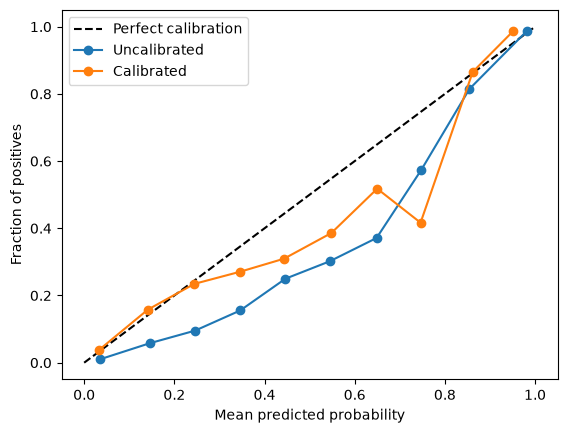

In [45]:
# Compare validation-set calibration curves.
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")

plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label="Uncalibrated"
)

plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label="Calibrated"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.legend()
plt.show()


## Threshold selection using validation set

Choose the classification threshold using calibrated probabilities on the validation set. The final test set remains untouched until final evaluation.

In [46]:
# Get calibrated probabilities for validation data.
val_prob = calibrated_model.predict_proba(x_val)[:, 1]

# Calculate precision, recall and F1 for candidate thresholds.
val_precision, val_recall, val_thresholds = precision_recall_curve(
    y_val,
    val_prob
)

val_f1_scores = (
    2 * val_precision[:-1] * val_recall[:-1]
    / (val_precision[:-1] + val_recall[:-1] + 1e-9)
)

# Select the threshold that maximizes validation F1.
best_index = int(np.argmax(val_f1_scores))
best_threshold = float(val_thresholds[best_index])

print(f"Selected threshold: {best_threshold:.6f}")
print(f"Validation F1 at selected threshold: {val_f1_scores[best_index]:.4f}")


Selected threshold: 0.585823
Validation F1 at selected threshold: 0.8225


## Final evaluation on untouched test set

Run this only after model selection, calibration and threshold selection are complete. Do not adjust the model or threshold based on these test results.


Calibrated XGBoost - Final Test Metrics
--------------------------
Accuracy  : 0.9360
Precision : 0.9442
Recall    : 0.7518
F1 Score  : 0.8371
ROC-AUC   : 0.9515

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5064
           1       0.94      0.75      0.84      1418

    accuracy                           0.94      6482
   macro avg       0.94      0.87      0.90      6482
weighted avg       0.94      0.94      0.93      6482



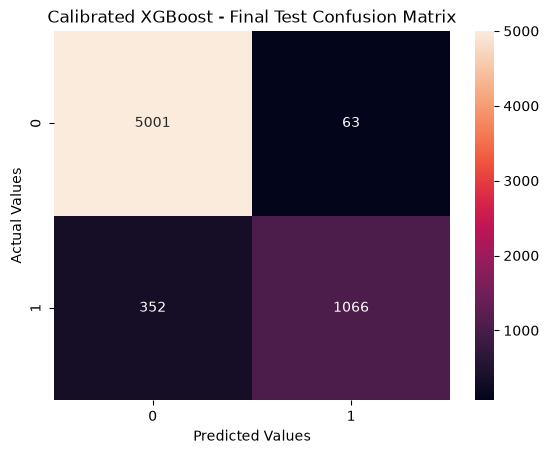

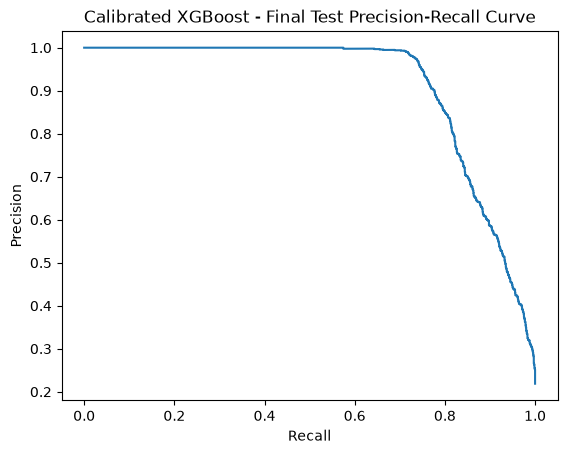

In [47]:
evaluate_model(
    "Calibrated XGBoost - Final Test",
    calibrated_model,
    x_test,
    y_test,
    best_threshold
)


## SHAP Interpretation --- Global & Local

In [48]:
#1. Install SHAP if not exists
!pip install shap
import shap


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\shrushti\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [49]:
# Get the trained XGBoost classifier from the tuned pipeline.
xgb_classifier = best_model.named_steps["classifier"]


In [50]:
# Transform the test data using the exact preprocessing fitted by best_model.
X_test_transformed = best_model.named_steps["preprocessor"].transform(x_test)


In [51]:
# Get feature names after one-hot encoding.
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()


In [52]:
#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [53]:
#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [54]:
#7. Calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[ 4.5325480e-02,  4.8114143e-02, -1.5894260e-01, ...,
        -7.1108667e-03, -2.5165722e-02,  1.2387773e-03],
       [-1.3433153e-02, -5.5065662e-01,  6.4595886e-02, ...,
        -7.2973743e-03, -3.1211602e-02, -2.5066026e-02],
       [-5.2257136e-02, -1.0000448e-01, -9.7915038e-02, ...,
        -8.4309699e-03,  6.1130640e-04, -1.0663387e-02],
       ...,
       [ 8.1940778e-02,  4.0822306e-01, -8.4815286e-02, ...,
        -7.3761158e-03, -2.6908098e-03,  2.7860100e-03],
       [-4.5599803e-02, -1.2847548e+00, -1.3518095e-01, ...,
        -8.8880938e-03, -4.5190733e-03, -9.0396097e-03],
       [-1.8078248e-01, -8.8253969e-01, -8.6759731e-02, ...,
        -9.1154659e-03, -3.3954967e-02, -2.5281126e-03]],
      shape=(6482, 26), dtype=float32)

### Global explanation 

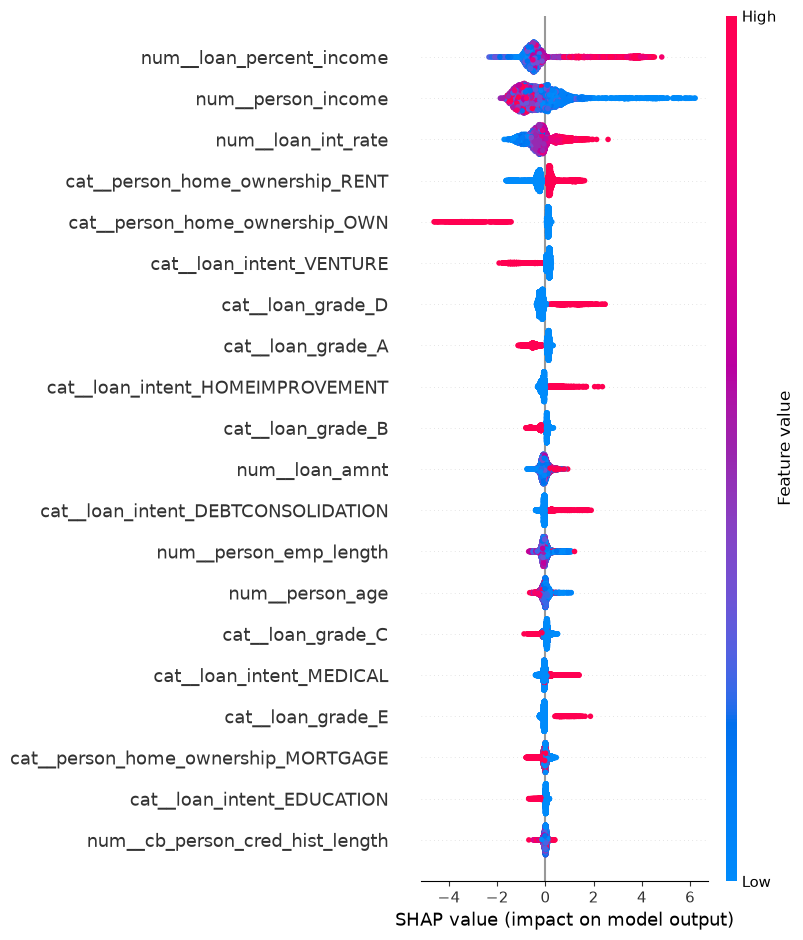

In [55]:
shap.summary_plot(shap_values, X_test_df)

### Local expantion 

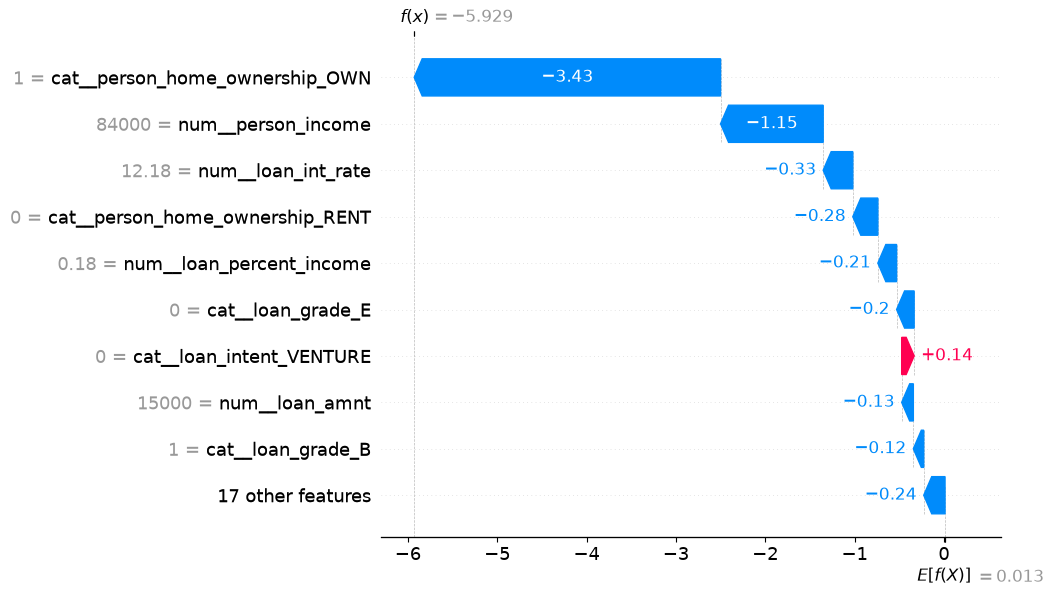

In [56]:
# 1. Pick one row to explain, e.g. the 5th applicant in the test set
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down.
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

## Analyzing False Positives & False Negatives

In [57]:
# Use the calibrated model and the validation-selected threshold for final test predictions.
y_test_probability = calibrated_model.predict_proba(x_test)[:, 1]
y_pred = (y_test_probability >= best_threshold).astype(int)


In [58]:
# Create a dataframe to compare actual and predicted test values.
result_df = x_test.copy()
result_df["actual"] = y_test
result_df["predicted"] = y_pred
result_df["predicted_probability"] = y_test_probability


In [59]:
# Identify false positives and false negatives on the untouched test set.
false_positive = result_df[
    (result_df["actual"] == 0) & (result_df["predicted"] == 1)
]

false_negative = result_df[
    (result_df["actual"] == 1) & (result_df["predicted"] == 0)
]


In [60]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")

False Positive : 63
False Negative : 352


## Save the final model 

In [61]:
import joblib

joblib.dump(calibrated_model, "credit_risk_model.pkl")

['credit_risk_model.pkl']

In [62]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']